**This notebook is used by Thibaut to learn how the Diego's branch works**
- Objectives
    - [x] Créer une base de données d'images
        - Fait. Images aériennes Suisse de 2017 à 2023 sur les glaciers rocheux actifs. 
        - Stockée sous `datamap['aerial_images_dir']` and `datamap['simon_swissimage_availables']`
    - Créer des pzones
    - Utiliser les scripts pour fabriquer des vignettes à partir de la base et les pzones
    - Produire des champs de déplacement à partir des vignettes
    - Produire des séries temporelles     

In [1]:
import geomulticorr as gmc
from pathlib import Path
import json
import geopandas as gpd
import os
with open('/home/duvanelt/datamap.json') as f:
    datamap = json.load(f)[0]

geomulticorr 0.5.2


In [2]:
# this will raise ValueError: Something else exists at.. during the next project loading
    # path_project = Path(datamap['rgcp_fusion'])
    # os.system(f'mkdir {path_project}')
    # session = gmc.open_gmc_session(path_project, epsg_code=2056)

# This works on 1st and nexts runs. 
    # path_project = Path(datamap['rgcp_fusion'])
    # if not path_project.exists():
    #     session = gmc.open_gmc_session(path_project, epsg_code=2056)

In [3]:
path_project = Path(datamap['rgcp_fusion'])
session = gmc.open_gmc_session(path_project, epsg_code=2056)

[GMC ✓] : GMC project structure found


[GMC ▸] : Session 'rgcp_fusion' initialized.


In [4]:
geodb_swiss_project = datamap['geodb_rgcp_swiss']
protomap_swiss_project = gpd.read_file(geodb_swiss_project, layer='extents-map_opt_')
protomap_swiss_project['file_path'] = protomap_swiss_project['filepath']
protomap_swiss_project.to_file(session.path_geodb, layer='Protomap')

,filepath,filename,th_path,acq_date,acq_year,xRes,yRes,bands,rows,cols,sensor,file_path,geometry
0,/run/media/duvanelt/LaCie/geodata_raster_dems_...,2025-01-01_0_swissimage-dop10_2025_2674-1159_0...,/run/media/duvanelt/LaCie/geodata_raster_dems_...,2025-01-01,2025-01-01,0.1,0.1,3,10000,10000,aerial,/run/media/duvanelt/LaCie/geodata_raster_dems_...,"POLYGON ((2674000 1160000, 2674000 1159000, 26..."
1,/run/media/duvanelt/LaCie/geodata_raster_dems_...,2025-01-01_0_swissimage-dop10_2025_2675-1156_0...,/run/media/duvanelt/LaCie/geodata_raster_dems_...,2025-01-01,2025-01-01,0.1,0.1,3,10000,10000,aerial,/run/media/duvanelt/LaCie/geodata_raster_dems_...,"POLYGON ((2675000 1157000, 2675000 1156000, 26..."


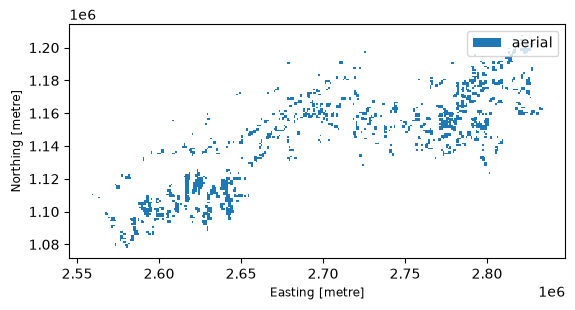

In [5]:
raster_bank = session.get_georasters_map()
raster_bank.plot(
    column="sensor",
    categorical=True,
    facecolor="none",
    legend=True,
)
raster_bank.head(2)

In [6]:
# Draw your polygon on the map, then run the next cell:
# get_gdf = session.draw_polygon_manually(raster_bank=raster_bank)

In [7]:
reset_pzones = False
if reset_pzones :
    pzones_swiss = gpd.read_file(geodb_swiss_project, layer='Pzones')
    pzones_swiss_selection = pzones_swiss[pzones_swiss.subset_for_gmcc_test_diego_branch == True]
    pzones_swiss_selection.to_file(session.path_geodb, layer='Pzones')

In [8]:
# # Change the EPSG of the other layers from the geodatabase
# for layer in ['Thumbs', 'Pairs']:
#     input_layer = gpd.read_file(session.path_geodb, layer=layer)
#     output_layer = input_layer.to_crs(epsg=2056)
#     output_layer.to_file(session.path_geodb, layer=layer)
    

In [9]:
session.get_pzones_overview()

,pz_name,pz_surf,subset_for_gmcc_test_diego_branch,geometry
0,rhone-left-up-572,50.0,True,"POLYGON ((2640514.347 1111769.731, 2641301.967..."
1,oberalp-pass-851,14.0,True,"POLYGON ((2698608.928 1160840.7, 2699079.198 1..."
2,engadin-low-1167,64.0,True,"POLYGON ((2806006.437 1178116.937, 2806925.8 1..."


In [10]:
session.sieve_bulk(raster_bank, target_resolution=0.1)

[GMC ℹ] : Map epsg : EPSG:2056
[GMC ℹ] : Target resolution: 0.1 (EPSG:2056)
[GMC ℹ] : Pzone: rhone-left-up-572
[GMC ℹ] : Intersecting rasters: 12


Output()

[GMC ℹ] : Pzone: oberalp-pass-851
[GMC ℹ] : Intersecting rasters: 16


Output()

[GMC ℹ] : Pzone: engadin-low-1167
[GMC ℹ] : Intersecting rasters: 5


Output()

                    sieve_bulk — processed thumbs                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┓
┃ Thumb                                  ┃ Sensor ┃ Res (m) ┃ Status ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━┩
│ engadin-low-1167_2019-01-01_aerial.tif │ aerial │     0.1 │ ✓ done │
│ engadin-low-1167_2022-01-01_aerial.tif │ aerial │     0.1 │ ✓ done │
│ engadin-low-1167_2025-01-01_aerial.tif │ aerial │     0.1 │ ✓ done │
└────────────────────────────────────────┴────────┴─────────┴────────┘

{'rhone-left-up-572': [PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/rhone-left-up-572/optical/rhone-left-up-572_2017-01-01_aerial.tif'),
  PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/rhone-left-up-572/optical/rhone-left-up-572_2020-01-01_aerial.tif'),
  PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/rhone-left-up-572/optical/rhone-left-up-572_2023-01-01_aerial.tif')],
 'oberalp-pass-851': [PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/oberalp-pass-851/optical/oberalp-pass-851_2019-01-01_aerial.tif'),
  PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/oberalp-pass-851/optical/oberalp-pass-851_2022-01-01_aerial.tif'),
  PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/oberalp-pass-851/optical/oberalp-pass-851_2025-01-01_aerial.tif')],
 'engadin-low-1167': [PosixPath('/mnt/Data_Part/data_rogi/labs/paper_geomulticorr/rgcp_fusion/engadin-low

In [14]:
session.update_thumbs()
session.get_thumbs_overview().head(3)  # check

,th_pz_name,th_path,th_sensor,th_date,th_year,th_valid,th_date_dec,th_date_datetime,geometry
0,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2019-01-01,2019,0,2019.0,2019-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."
1,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2022-01-01,2022,0,2022.0,2022-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."
2,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2025-01-01,2025,0,2025.0,2025-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."


In [18]:
session.validate_all_thumbs().head(3)

,th_pz_name,th_path,th_sensor,th_date,th_year,th_valid,th_date_dec,th_date_datetime,geometry
0,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2019-01-01,2019,1,2019.0,2019-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."
1,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2022-01-01,2022,1,2022.0,2022-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."
2,engadin-center-358,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,aerial,2025-01-01,2025,1,2025.0,2025-01-01,"POLYGON ((2806845.9 1177139.7, 2806845.9 11771..."


In [17]:
session.update_pairs_with_strategy(
    strategy="redundancy",  # or "sequential"
    max_step=1,             # 1 = adjacent pairs only; 2 = skip-one, etc.
)

AttributeError: 'Session' object has no attribute 'update_pairs_with_strategy'

In [19]:
session.explore_pairs_strategy(
    strategy='consecutive',
    max_step=1
)

In [21]:
session.update_pairs()
session.get_pairs_overview()

[GMC ℹ] : Updating pairs for PZone: 'rhone-left-up-572'
[GMC ℹ] : Updating pairs for PZone: 'oberalp-pass-851'
[GMC ℹ] : Updating pairs for PZone: 'engadin-low-1167'


,pa_pz_name,pa_path,pa_left_date,pa_left_datetime,pa_left_sensor,pa_right_date,pa_right_datetime,pa_right_sensor,pa_dt_days,pa_dt_months,pa_dt_years,pa_direction,pa_disparity_f_path,pa_status,geometry
0,rhone-left-up-572,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2017-01-01,2017-01-01,aerial,2020-01-01,2020-01-01,aerial,1095,35.98,2.9979,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2640514.3 1111769.7, 2640514.3 11117..."
1,rhone-left-up-572,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2020-01-01,2020-01-01,aerial,2023-01-01,2023-01-01,aerial,1096,36.01,3.0007,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2640514.3 1111769.7, 2640514.3 11117..."
2,oberalp-pass-851,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2019-01-01,2019-01-01,aerial,2022-01-01,2022-01-01,aerial,1096,36.01,3.0007,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2698608.9 1160840.7, 2698608.9 11608..."
3,oberalp-pass-851,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2022-01-01,2022-01-01,aerial,2025-01-01,2025-01-01,aerial,1096,36.01,3.0007,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2698608.9 1160840.7, 2698608.9 11608..."
4,engadin-low-1167,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2019-01-01,2019-01-01,aerial,2022-01-01,2022-01-01,aerial,1096,36.01,3.0007,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2806006.4 1178116.9, 2806006.4 11781..."
5,engadin-low-1167,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,2022-01-01,2022-01-01,aerial,2025-01-01,2025-01-01,aerial,1096,36.01,3.0007,forward,/mnt/Data_Part/data_rogi/labs/paper_geomultico...,empty,"POLYGON ((2806006.4 1178116.9, 2806006.4 11781..."


In [24]:
pair_test = session.get_pairs()[0]
pair_test

---------
type      : GMC_Pair
pzone     : rhone-left-up-572
left      : 2017-01-01-aerial
right     : 2020-01-01-aerial
direction : forward
dt        : 1095 days / 35.98 months / 2.9979 years
status    : empty
---------

In [25]:
pair_test.clip()

True

In [26]:
pair_test.launch_correlation(
    corr_algorithm='asp_bm',
    corr_kernel_size=7
)

TypeError: ASP.run_correlation() got an unexpected keyword argument 'params_file_path'